# Phase 1: Supervised Learning — Customer Churn

## 1. Model Selection & Rationale

### 1.1 Problem Type and Dataset Summary
We are predicting whether a customer will churn. This is a binary classification task (`churn_flag`: 1 = churned, 0 = retained).

The dataset has 100,000 rows and 18 columns. We removed `customer_id` because it is only an identifier. We also removed `churn_risk` because it is built from the target. High always means churned and Low always means retained, so keeping it would leak the answer. That leaves 15 predictors: 10 numeric and 5 categorical.

Part A found no missing values. The classes are fairly balanced: 46.22% churned and 53.78% retained.

### 1.2 Logistic Regression

We chose Logistic Regression as our baseline model because it is simple, interpretable, and suitable for binary classification. It estimates the probability that a customer will churn.

Our Part A analysis supports this choice. `recency_days` has a strong correlation with churn (r = 0.77), and the classes are fairly balanced. The dataset is also large enough to train the model reliably.

Logistic Regression has some limitations. It assumes a linear relationship between the features and the log-odds of churn, so it may miss non-linear patterns and interactions. Some features are skewed (such as `total_spent`), while others may be highly correlated (such as `purchase_frequency` and `website_visits`), which can affect coefficient stability.

We use StandardScaler to standardize numerical features and help the model train more consistently. We will compare Logistic Regression with Random Forest to see whether a more flexible model performs better.
### 1.3 Random Forest Classifier
We chose Random Forest to test whether a more flexible model does better. It can learn non-linear patterns and feature interactions, and it works well with a mix of numeric and categorical features. It does not need scaling and is not sensitive to skewed features.

It also gives feature importance scores, which helps us see which factors drive churn.

The trade-off is that it is harder to explain than Logistic Regression and slower to train.

### 1.4 Why This Pair
Logistic Regression is the simple, interpretable baseline. Random Forest is the flexible model. We will compare them on the same data split with the same metrics. This will show whether the extra complexity is worth it for this problem.

## 2. Implementation & Training Code

In [8]:
import pandas as pd

# Load the training and testing datasets
train = pd.read_csv("Dataset/Processed/train_processed.csv")
test = pd.read_csv("Dataset/Processed/test_processed.csv")

# Display dataset dimensions
print("Training data:", train.shape)
print("Testing data:", test.shape)

# Preview the training data
train.head()

Training data: (80000, 31)
Testing data: (20000, 31)


,categorical__age_group_18-24,categorical__age_group_25-34,categorical__age_group_35-44,categorical__age_group_45-54,categorical__age_group_55+,categorical__gender_Female,categorical__gender_Male,categorical__gender_Other,categorical__region_Central,categorical__region_East,...,numerical__avg_order_value,numerical__total_spent,numerical__recency_days,numerical__website_visits,numerical__discount_usage_rate,numerical__email_open_rate,numerical__cart_abandonment_rate,numerical__loyalty_score,numerical__engagement_score,churn_flag
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,-0.761699,-0.606332,-1.584302,-0.565563,-0.396897,0.471760,-0.266327,-0.058059,0.527209,0
1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,-0.638620,-0.234016,-1.422761,-0.005819,0.155764,-0.547079,-1.480694,1.135398,0.616482,0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,-1.317743,-0.507178,-0.444010,-0.234805,0.432095,1.327584,-0.353068,-1.713498,1.211637,0
3,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,-0.426651,-0.431940,0.173648,-0.412905,0.938701,0.757035,0.297486,-0.866529,0.348663,1
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-1.622068,-0.661917,-0.634059,-0.654613,-0.489007,1.694366,0.470966,-1.559504,0.914059,0


In [10]:
# Separate features and target

X_train = train.drop(columns=["churn_flag"])
y_train = train["churn_flag"]

X_test = test.drop(columns=["churn_flag"])
y_test = test["churn_flag"]

# Display the dimensions
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (80000, 30)
y_train: (80000,)
X_test: (20000, 30)
y_test: (20000,)


In [ ]:
print("Features used for training:")
print(X_train.columns.tolist())

Features used for training:
['age_group', 'gender', 'region', 'customer_segment', 'preferred_channel', 'purchase_frequency', 'avg_order_value', 'total_spent', 'recency_days', 'website_visits', 'discount_usage_rate', 'email_open_rate', 'cart_abandonment_rate', 'loyalty_score', 'engagement_score']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identify categorical and numerical features
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Create the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Build the Logistic Regression pipeline
lr_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Logistic Regression pipeline created successfully!")

Categorical features: 5
Numerical features: 10
Logistic Regression pipeline created successfully!


In [ ]:
# Train the Logistic Regression model
lr_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Predict customer churn using the test data
y_pred = lr_pipeline.predict(X_test)

# Display the first 10 predictions
print("Predicted:", y_pred[:10])
print("Actual:   ", y_test.iloc[:10].values)

Predicted: [1 0 0 0 0 1 1 1 0 0]
Actual:    [1 0 0 0 0 1 1 1 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predict churn probabilities
y_prob = lr_pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

# Display results
print("Logistic Regression - Baseline Results")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Logistic Regression - Baseline Results
Accuracy:  0.9459
Precision: 0.9419
Recall:    0.9410
F1-score:  0.9415
ROC-AUC:   0.9904


In [11]:
#Model 2 - Random Forest
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

#Create preprocessing for random forest


#Create Random Forest Pipeline
rf_pipeline = Pipeline(
    steps=[
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        ))
    ]
)

#Train Random Forest model
rf_pipeline.fit(X_train,y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [13]:
#Model 2 - Random Forest

#Predict customer churn
rf_y_pred = rf_pipeline.predict(X_test)

#Display the first 15 predictions
print("Predicted:",rf_y_pred[:15])
print("Actual:",y_test.iloc[:15].values)

Predicted: [0 1 0 0 0 1 1 1 0 0 1 0 0 0 0]
Actual: [1 0 0 0 0 1 1 1 0 0 1 0 0 0 0]


In [14]:
#Model 2 - Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Get predicted churn probabilities
rf_y_prob = rf_pipeline.predict_proba(X_test)[:, 1]

# Calculate metrics
rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_precision = precision_score(y_test, rf_y_pred)
rf_recall = recall_score(y_test, rf_y_pred)
rf_f1 = f1_score(y_test, rf_y_pred)
rf_roc_auc = roc_auc_score(y_test, rf_y_prob)

# Display results
print("Random Forest - Baseline Results")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_roc_auc, 4))

Random Forest - Baseline Results
Accuracy: 0.9421
Precision: 0.9389
Recall: 0.9355
F1-score: 0.9372
ROC-AUC: 0.988


# 3. Hyperparameter Tuning Process & Results

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define hyperparameter values
param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__solver": ["lbfgs", "liblinear"]
}

# Define 5-Fold Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform Hyperparameter Tuning
grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

# Train and find the best parameters
grid_search.fit(X_train, y_train)

# Display the results
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-score:", round(grid_search.best_score_, 4))

Best Parameters: {'model__C': 0.01, 'model__solver': 'lbfgs'}
Best CV F1-score: 0.9395


In [15]:
# Model 2 - Random Forest
# 5-Fold Cross-Validation

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold


############# importing selected data and preparing the pipeline #############


# Load selected training data before preprocessing (to prevent data leakage)
rf_train_selected = pd.read_csv(
    "Dataset/Processed/train_selected.csv"
)

# Separate features and target
rf_X_train = rf_train_selected.drop(columns=["churn_flag"])
rf_y_train = rf_train_selected["churn_flag"]

# Identify feature types
rf_numerical_features = rf_X_train.select_dtypes(
    include=["number"]
).columns.tolist()

rf_categorical_features = rf_X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preprocessing inside the Pipeline
rf_preprocessing_cv = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), rf_numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         rf_categorical_features)
    ]
)

# Random Forest Pipeline for Cross-Validation
rf_cv_pipeline = Pipeline(
    steps=[
        ("preprocessing", rf_preprocessing_cv),
        ("model", RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ]
)

###################################################################


# Hyperparameter grid
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20, None],
    "model__min_samples_split": [2, 5]
}

# 5-Fold Cross-Validation
rf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
rf_grid_search = GridSearchCV(
    estimator=rf_cv_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=rf_cv,
    n_jobs=-1,
    verbose=1
)

# Run tuning
rf_grid_search.fit(rf_X_train, rf_y_train)

# Display results
print("Best Parameters:", rf_grid_search.best_params_)
print("Best CV F1-score:", round(rf_grid_search.best_score_, 4))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV F1-score: 0.9347


### Hyperparameter Tuning Discussion

F1-score was selected as the evaluation metric for hyperparameter tuning because it balances precision and recall. This is important in customer churn prediction, where both identifying customers at risk of leaving and reducing incorrect predictions are valuable.

#####Logistic Regression:
Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation. The best parameters were C = 0.01 and solver = lbfgs, achieving a cross-validation F1-score of 0.9395.

The tuned Logistic Regression model achieved a test F1-score of 0.9409, compared with 0.9415 for the baseline model. The difference was small, indicating that tuning did not provide a meaningful improvement in test performance.

#####Random Forest:

Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation. The parameters n_estimators, max_depth, and min_samples_split were evaluated using F1-score as the selection metric.

The best parameters were n_estimators = 200, max_depth = None, and min_samples_split = 2, achieving a cross-validation F1-score of 0.9347.

These parameters were selected based on the highest mean F1-score across the five validation folds.

## 4. Evaluation Metrics & Visualizations

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Get the best Logistic Regression model
best_lr_model = grid_search.best_estimator_

# Make predictions
y_pred_tuned = best_lr_model.predict(X_test)
y_prob_tuned = best_lr_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned)
tuned_recall = recall_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)
tuned_roc_auc = roc_auc_score(y_test, y_prob_tuned)

# Display results
print("Logistic Regression - Tuned Results")
print(f"Accuracy:  {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall:    {tuned_recall:.4f}")
print(f"F1-score:  {tuned_f1:.4f}")
print(f"ROC-AUC:   {tuned_roc_auc:.4f}")

Logistic Regression - Tuned Results
Accuracy:  0.9455
Precision: 0.9418
Recall:    0.9401
F1-score:  0.9409
ROC-AUC:   0.9904


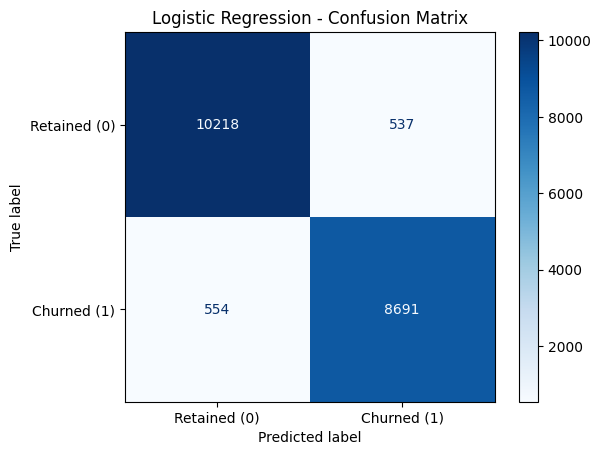

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion Matrix for Tuned Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=["Retained (0)", "Churned (1)"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

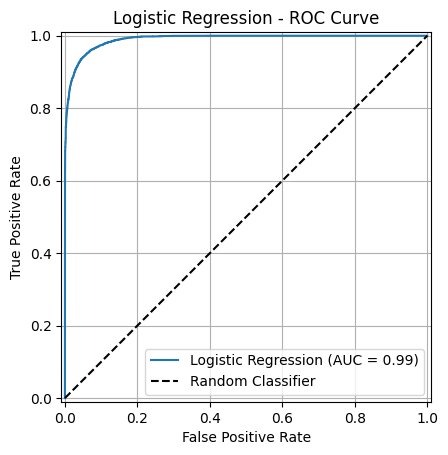

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot ROC Curve for Tuned Logistic Regression
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_tuned,
    name="Logistic Regression"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("Logistic Regression - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
#Model 2 - Random Forest

# Load selected test data before preprocessing
rf_test_selected = pd.read_csv(
    "Dataset/Processed/test_selected.csv"
)

# Separate features and target
rf_X_test = rf_test_selected.drop(columns=["churn_flag"])
rf_y_test = rf_test_selected["churn_flag"]

# Get the best tuned Random Forest model
rf_tuned_model = rf_grid_search.best_estimator_

# Make predictions
rf_tuned_pred = rf_tuned_model.predict(rf_X_test)
rf_tuned_prob = rf_tuned_model.predict_proba(rf_X_test)[:, 1]

# Calculate metrics
rf_tuned_accuracy = accuracy_score(rf_y_test, rf_tuned_pred)
rf_tuned_precision = precision_score(rf_y_test, rf_tuned_pred)
rf_tuned_recall = recall_score(rf_y_test, rf_tuned_pred)
rf_tuned_f1 = f1_score(rf_y_test, rf_tuned_pred)
rf_tuned_roc_auc = roc_auc_score(rf_y_test, rf_tuned_prob)

# Display results
print("Random Forest - Tuned Results")
print("Accuracy:", round(rf_tuned_accuracy, 4))
print("Precision:", round(rf_tuned_precision, 4))
print("Recall:", round(rf_tuned_recall, 4))
print("F1-score:", round(rf_tuned_f1, 4))
print("ROC-AUC:", round(rf_tuned_roc_auc, 4))


Random Forest - Tuned Results
Accuracy: 0.9424
Precision: 0.9387
Recall: 0.9365
F1-score: 0.9376
ROC-AUC: 0.9882


### Random Forest - Baseline vs Tuned Comparison

The tuned Random Forest model achieved slightly better performance than the baseline model in four out of five evaluation metrics.

Accuracy increased from 0.9421 to 0.9424, recall from 0.9355 to 0.9365, F1-score from 0.9372 to 0.9376, and ROC-AUC from 0.9880 to 0.9882.

However, precision decreased slightly from 0.9389 to 0.9387.

Overall, hyperparameter tuning was associated with a small improvement in performance, particularly in recall, which is important for identifying customers at risk of churn.

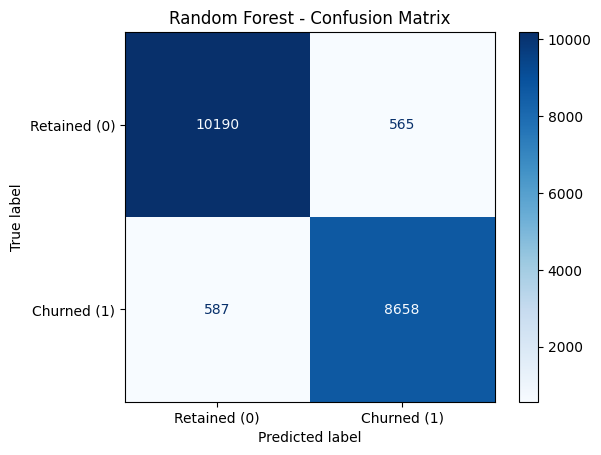

In [20]:
#Model 2 - Random Forest

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion Matrix for Tuned Random Forest
ConfusionMatrixDisplay.from_predictions(
    rf_y_test,
    rf_tuned_pred,
    display_labels=["Retained (0)", "Churned (1)"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

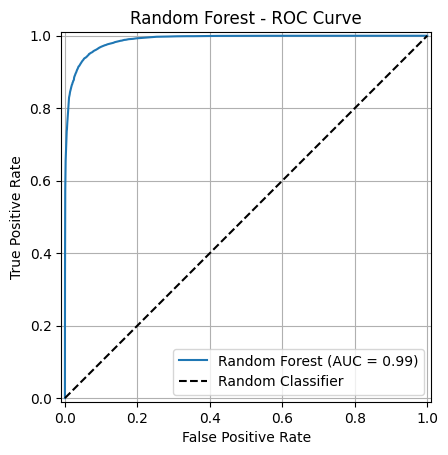

In [21]:
#Model 2 - Random Forest

import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot ROC Curve for Tuned Random Forest
RocCurveDisplay.from_predictions(
    rf_y_test,
    rf_tuned_prob,
    name="Random Forest"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("Random Forest - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

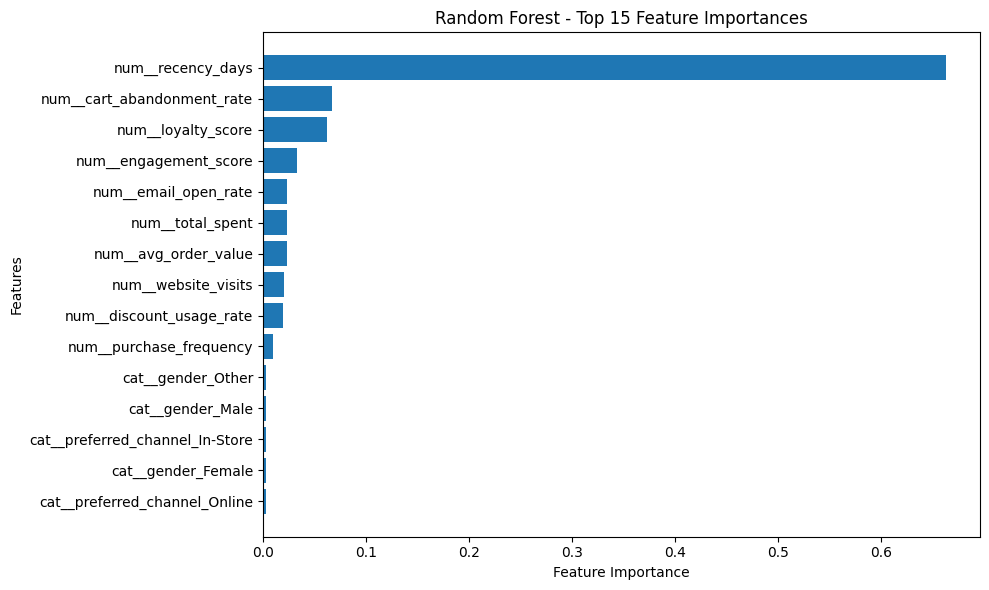

In [22]:
# Model 2 - Random Forest

import pandas as pd
import matplotlib.pyplot as plt

# best tuned Random Forest model
rf_tuned_model = rf_grid_search.best_estimator_

# feature names after preprocessing
rf_feature_names = rf_tuned_model.named_steps[
    "preprocessing"
].get_feature_names_out()

# feature importance scores
rf_importances = rf_tuned_model.named_steps[
    "model"
].feature_importances_

# Create DataFrame
rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})

# Select the top 15 most important features
rf_top_15 = rf_importance_df.nlargest(
    15, "Importance"
).sort_values("Importance")

# Plot Feature Importance
plt.figure(figsize=(10, 6))
plt.barh(rf_top_15["Feature"], rf_top_15["Importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest - Top 15 Feature Importances")
plt.tight_layout()
plt.show()


### Misclassification Analysis



The tuned **Logistic Regression** model incorrectly classified 1,091 out of 20,000 customers.

- False Positives (537): Customers predicted to churn who actually stayed. This may lead to unnecessary retention offers.
- False Negatives (554): Customers predicted to stay who actually churned. This is particularly important because the business may miss opportunities to retain these customers.



The tuned **Random Forest** model misclassified 1152 out of 20000 customers, achieving an accuracy of 94.24%.

- False Positives (565): Customers predicted to churn who actually stayed. This may lead to unnecessary retention offers.
- False Negatives (587): Customers predicted to stay who actually churned. This is particularly important because the business may miss opportunities to retain these customers.

Compared with Logistic Regression, which misclassified 1,091 customers, Random Forest made 61 more classification errors.

For our customer retention system, reducing false negatives is valuable because identifying customers at risk of churn allows the business to take preventive actions.

### ROC Curve Analysis

Both Logistic Regression and Random Forest achieved high ROC-AUC scores, indicating strong ability to distinguish between churned and retained customers.

Logistic Regression achieved a ROC-AUC of 0.9904, slightly higher than Random Forest's 0.9882.

### ROC Curve Analysis Feature Importance Analysis - Random Forest

The Random Forest feature importance plot shows that recency_days is the most influential feature in predicting customer churn, with a substantially higher importance score than the other features.

cart_abandonment_rate and loyalty_score are the next most important features, followed by engagement_score and email_open_rate.

These results suggest that recent customer activity, shopping behavior, and loyalty are important factors in the model's churn predictions.

Categorical features, such as gender and preferred channel, have relatively low individual importance scores.


## 5. Model Comparison & Analysis

In [23]:
import pandas as pd

# Compare Logistic Regression with Random Forest
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc
    ],
    "Random Forest": [
        rf_tuned_accuracy,
        rf_tuned_precision,
        rf_tuned_recall,
        rf_tuned_f1,
        rf_tuned_roc_auc
    ]

})

comparison

NameError: name 'tuned_accuracy' is not defined

In [24]:
# Model 2 - Random Forest

# Analyze misclassifications by customer segment

#Read selected data (before hot encoding to fing categories name)
error_analysis = pd.read_csv("Dataset/Processed/test_selected.csv")

error_analysis["LR_Error"] = (lr_tuned_pred != error_analysis["churn_flag"].to_numpy()).astype(int)
error_analysis["RF_Error"] = (rf_tuned_pred != error_analysis["churn_flag"].to_numpy()).astype(int)

segment_errors = error_analysis.groupby("customer_segment").agg(
    Total_Customers=("churn_flag", "size"),
    LR_Errors=("LR_Error", "sum"),
    RF_Errors=("RF_Error", "sum"),
    LR_Error_Rate=("LR_Error", "mean"),
    RF_Error_Rate=("RF_Error", "mean")
)

segment_errors["LR_Error_Rate"] = (segment_errors["LR_Error_Rate"] * 100).round(2)
segment_errors["RF_Error_Rate"] = (segment_errors["RF_Error_Rate"] * 100).round(2)

display(segment_errors)

,Total_Customers,RF_Errors,RF_Error_Rate
customer_segment,,,
Loyal,4957,291,5.87
New,5137,309,6.02
Returning,5017,285,5.68
VIP,4889,267,5.46


In [ ]:

import time
from sklearn.base import clone

# Create a new copy of the tuned Random Forest pipeline
rf_timing_model = clone(rf_grid_search.best_estimator_)

# Measure training time
start = time.perf_counter()
rf_timing_model.fit(rf_X_train, rf_y_train)
rf_training_time = time.perf_counter() - start

# Measure prediction time
start = time.perf_counter()
rf_timing_model.predict(rf_X_test)
rf_prediction_time = time.perf_counter() - start

print(f"Random Forest Training Time: {rf_training_time:.4f} seconds")
print(f"Random Forest Prediction Time: {rf_prediction_time:.4f} seconds")


### Model Comparison & Analysis

Both Logistic Regression and Random Forest achieved strong performance in predicting customer churn. However, Logistic Regression slightly outperformed Random Forest across all five evaluation metrics.

Logistic Regression achieved a higher **accuracy** of 0.9455 compared with 0.9424 for Random Forest. This means that Logistic Regression correctly classified more customers in the test dataset.

It also achieved higher precision (0.9418 vs. 0.9387) and recall (0.9401 vs. 0.9365). Similarly, Logistic Regression achieved a higher F1-score (0.9409 vs. 0.9376) and ROC-AUC (0.9904 vs. 0.9882).

Overall, the performance differences were relatively small, but Logistic Regression consistently achieved better results on the test set, making it the better model in terms of accuracy.

Logistic Regression is easier to **interpret** because its coefficients help explain how different features affect churn predictions. In contrast, Random Forest uses multiple decision trees, making its predictions more difficult to explain. However, feature importance can help identify which features are most important in Random Forest predictions.

## 6. Conclusion: Best Model Selection & Reasoning

Based on the evaluation results, Logistic Regression was selected as the preferred model for the customer churn prediction system.

The tuned Logistic Regression model achieved an F1-score of 0.9409 and a ROC-AUC of 0.9904, compared with 0.9376 and 0.9882 for the tuned Random Forest model. It also achieved higher accuracy, precision, and recall.

Additionally, Logistic Regression made fewer classification errors, misclassifying 1,091 customers compared with 1,152 for Random Forest. It also produced fewer false negatives (554 compared with 587), which is particularly important for identifying customers at risk of churn.

Logistic Regression is also easier to interpret because its coefficients can help explain how different features affect churn predictions.

Therefore, Logistic Regression was selected for the final system because it provides slightly better predictive performance, fewer classification errors, and greater interpretability, making it suitable for supporting customer retention decisions.

## 7. Next Steps for Phase 2 Integration
In Phase 2, we will use the tuned Logistic Regression model as the core of our system. It gives each customer a churn probability, and it was our best model in Phase 1. We will use these probabilities to help the business decide which customers to contact first.

We plan to build on it in three ways:
- **Customer segments:** we will use clustering to group customers. These groups will add context to each prediction.
- **Dashboard:** we will show each customer's churn risk, the confidence of the prediction, and the main factors behind it. Logistic Regression coefficients make these factors easy to explain.
- **Generative AI:** we will turn the predictions into short, clear summaries for decision-makers.

Because the model still makes errors (1,091 out of 20,000 test customers), a person should review its recommendations before any action is taken. We also need to monitor the model over time, because customer behaviour can change and its accuracy may drop.